# BreaKHis v3 — are histopathology CNN "wins" reliable under patient shift?

A patient-grouped, multi-fold study of **stain-shift robustness, threshold transfer and abstention** on BreaKHis (benign vs malignant). Built from what runs 1 and 2 showed:

* rankings flip between splits (run 1 vs run 2), so single-split comparisons are not trustworthy → **5-fold patient-grouped CV (+ optional repeats) with patient-clustered bootstrap CIs**;
* ColorJitter *helped* clean accuracy in run 2, but its robustness looked **family-specific**, and the stain-shift test was circular (the test shift reused the HED training augmentation) → **independent shift family: Reinhard transfer to the stain statistics of *other real patients***, plus a `both` augmentation to test whether the families can be combined;
* validation-tuned "99 % sensitivity" thresholds delivered only 0.74–0.92 recall on unseen patients, and temperature scaling did not help → **patient-level conformal risk control (CRC)** vs naive threshold choices;
* max-softmax abstention is the standard baseline → **stain-perturbation test-time disagreement** as an uncertainty signal, with a dihedral-TTA control;
* adversarial robustness is already well documented in computational pathology (Ghaffari Laleh et al., *Nat. Commun.* 2022), so here it is only a **small sanity check**.

### Hypotheses to test (not results)
| | Hypothesis | Where |
|---|---|---|
| H1 | Robustness from one augmentation family does not transfer to another; `both` may or may not close the gap | §9, §10 |
| H2 | Validation-tuned sensitivity targets under-deliver on new patients; patient-level CRC meets its target in expectation | §12 |
| H3 | Disagreement across HED-perturbed views detects errors better than max-softmax, especially under independent (Reinhard) shift | §13 |
| H4 | Model/augmentation rankings are unstable across patient folds | §11 |

Report whatever comes out. If a hypothesis fails, that is a finding.

### Runtime (read this)
* All augmentation and shift operations run **on the GPU** from a cached uint8 tensor, so training is faster than runs 1–2. I could not time it on Kaggle hardware: do a `QUICK_TEST=True` run, then `FOLDS_TO_RUN=[0]`, and extrapolate.
* Full default = 5 folds × 2 models × 4 augmentations = 40 runs. Every finished run is **pickled to `/kaggle/working/runs/`** and skipped on re-run (`RESUME=True`), so you can split the work across sessions (e.g. `FOLDS_TO_RUN=[0,1]`, then `[2,3,4]`; save the `runs/` folder as a Kaggle dataset between sessions and attach it as input, or copy the pickles back).
* Analysis sections 8+ only need the pickles, not the GPU.

**Setup:** attach BreaKHis (`ambarish/breakhis`), GPU on, Internet on (ImageNet weights). Optional: attach an external benign/malignant set and set `EXTERNAL_DIR`.

## 1. Imports and config

In [4]:
import os, re, glob, time, math, random, pickle, warnings, itertools
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from scipy.stats import kendalltau
try: from IPython.display import display
except Exception: display = print
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")

CFG = dict(
    MODELS=["densenet121", "efficientnet_b0"],          # also: resnet50, resnext50, mobilenet_v2, vgg16, alexnet, convnext_tiny, shufflenet
    AUGS=["geom", "jitter", "hed", "both"],             # basic | geom | jitter (geom+ColorJitter) | hed (geom+HED) | both (all three)
    SEEDS=[42],                                         # each seed = a different patient-grouped fold assignment (add e.g. 43, 44 for repeats)
    N_FOLDS=5, FOLDS_TO_RUN=[0, 1, 2, 3, 4],
    EPOCHS=12, PATIENCE=3, BATCH=32, LR_BACKBONE=5e-5, LR_HEAD=5e-4, WD=1e-2, LABEL_SMOOTH=0.1,
    IMG=224, PRETRAINED=True, FREEZE_BACKBONE=False,
    HED_SIGMA=0.1, JITTER=(0.3, 0.3, 0.3, 0.1), ROT=30,
    # test-time shift families and severities. Reinhard level = interpolation toward the stain statistics of a RANDOM OTHER
    # training-set image (0 = unchanged, 1 = full transfer): an independent, data-grounded shift (not used in any training aug).
    SHIFT={"HED": [0.0, 0.1, 0.2, 0.3, 0.4], "ColorJitter": [0.0, 0.1, 0.2, 0.3, 0.4], "Reinhard": [0.0, 0.25, 0.5, 0.75, 1.0]},
    SHIFT_REF={"HED": 0.3, "ColorJitter": 0.3, "Reinhard": 1.0},
    # abstention: K stain-perturbed (HED) views vs K dihedral views (control), evaluated clean and under shift
    TTA_K=6, TTA_SIGMA=0.15,
    ABSTAIN_CONDS=[("clean", 0.0), ("Reinhard", 0.5), ("Reinhard", 1.0), ("HED", 0.3)],
    RUN_ADV=True, ADV_FOLDS=[0], ROB_N=150, EPS=[1.0, 2.0], PGD_STEPS=7,   # small sanity check only (first seed, listed folds)
    ALPHAS=[0.02, 0.05, 0.10, 0.20],                    # target miss rates (= 1 - target sensitivity)
    N_BOOT=500,
    EXTERNAL_DIR=None,                                  # e.g. "/kaggle/input/some-set": subfolders named benign/ and malignant/
    RESUME=True, QUICK_TEST=False,
)
ROOT = "/kaggle/input"
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RUN_DIR = f"{OUT}/runs"; os.makedirs(RUN_DIR, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD_T = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
def normalize_px(x): return (x - MEAN_T) / STD_T
print("Device:", device, "| AMP:", use_amp)

Device: cuda | AMP: True


## 2. Find images, build the table, verify the patient key

In [5]:
files = [f for f in glob.glob(f"{ROOT}/**/*.png", recursive=True)
         if (f"{os.sep}benign{os.sep}" in f or f"{os.sep}malignant{os.sep}" in f)
         and os.path.basename(f).upper().startswith("SOB_")
         and not (CFG["EXTERNAL_DIR"] and f.startswith(CFG["EXTERNAL_DIR"]))]
assert files, "No BreaKHis images found - attach the BreaKHis dataset via '+ Add Input'."
NAME_RE = re.compile(r"SOB_([BM])_([A-Z]+)-(\d+-[0-9A-Za-z]+)-(\d+)-\d+", re.I)

def parse(f):
    parts = f.split(os.sep); m = NAME_RE.search(os.path.basename(f))
    sub = m.group(2).upper() if m else "NA"; pid = m.group(3) if m else os.path.basename(os.path.dirname(os.path.dirname(f)))
    return dict(path=f, label=int("malignant" in parts), subtype=sub, pid_raw=pid,
                patient=f"{pid}|{sub}",                      # id + subtype: a patient has one subtype, so this can only split colliding ids, never leak
                magnification=(m.group(4) + "X") if m else os.path.basename(os.path.dirname(f)))

df = pd.DataFrame([parse(f) for f in files]).sort_values("path").reset_index(drop=True)
df["gi"] = np.arange(len(df))                                 # row index into the image cache
chk = df.groupby("patient").agg(n_label=("label", "nunique"))
assert chk.n_label.max() == 1, "a patient key maps to both classes"
print(f"{len(df)} images | raw ids: {df.pid_raw.nunique()} | patient keys: {df.patient.nunique()} "
      f"(BreaKHis documents 82 patients) | benign {int((df.label==0).sum())} / malignant {int((df.label==1).sum())}")
dup = df.groupby("pid_raw").subtype.nunique(); print("raw ids shared by >1 subtype (id collisions):", dup[dup > 1].index.tolist())
CLASS_NAMES = ["Benign", "Malignant"]

7909 images | raw ids: 81 | patient keys: 82 (BreaKHis documents 82 patients) | benign 2480 / malignant 5429
raw ids shared by >1 subtype (id collisions): ['14-13412']


## 3. Cache all images once as a uint8 tensor (squashed to IMG×IMG, as in runs 1–2)

In [6]:
def load_uint8(paths, size):
    bil = getattr(Image, "Resampling", Image).BILINEAR
    f = lambda p: np.asarray(Image.open(p).convert("RGB").resize((size, size), bil))
    with ThreadPoolExecutor(8) as ex: arr = list(ex.map(f, list(paths)))
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()

t0 = time.time(); X_all = load_uint8(df.path, CFG["IMG"]); print("cache", tuple(X_all.shape), f"{X_all.numel()/1e9:.2f} GB, {time.time()-t0:.0f}s")

X_ext = y_ext = None
if CFG["EXTERNAL_DIR"]:
    ef = [f for f in glob.glob(f"{CFG['EXTERNAL_DIR']}/**/*", recursive=True)
          if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")) and re.search(r"(benign|malignant)", f, re.I)]
    y_ext = np.array([int("malignant" in f.lower().replace("benign", "")) for f in ef])
    X_ext = load_uint8(ef, CFG["IMG"]); print("external:", len(ef), "images, malignant frac", y_ext.mean().round(3))

cache (7909, 3, 224, 224) 1.19 GB, 191s


## 4. Colour operations (all on GPU, torch)

* **HED** (haematoxylin–eosin–DAB) stain-concentration scale/shift — training augmentation `hed` and test-shift family "HED".
* **ColorJitter** (brightness / contrast / saturation, + hue via YIQ rotation in training) — training augmentation `jitter` and test-shift family "ColorJitter".
* **Reinhard** transfer in lαβ space toward the statistics of *another real image* — **test-time only**, never used in training, so it is an independent shift family.

In [7]:
RGB_FROM_HED = torch.tensor([[0.65, 0.70, 0.29], [0.07, 0.99, 0.11], [0.27, 0.57, 0.78]])
HED_FROM_RGB = torch.linalg.inv(RGB_FROM_HED)

def hed_perturb(x, alpha, beta):                      # x: B,3,H,W in [0,1]; alpha,beta: B,3,1,1
    R, Ri = RGB_FROM_HED.to(x.device), HED_FROM_RGB.to(x.device)
    od = -torch.log(x.clamp(min=1e-3))
    c = torch.einsum("bchw,cd->bdhw", od, Ri) * alpha + beta
    return torch.exp(-torch.einsum("bdhw,dc->bchw", c, R)).clamp(0, 1)

def _gray(t): return 0.299 * t[:, 0:1] + 0.587 * t[:, 1:2] + 0.114 * t[:, 2:3]
def color_shift(x, b, c, s):                          # brightness / contrast / saturation factors, each B,1,1,1
    x = (x * b).clamp(0, 1)
    m = _gray(x).mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - m) * c + m).clamp(0, 1)
    g = _gray(x)
    return (g + (x - g) * s).clamp(0, 1)

YIQ = torch.tensor([[0.299, 0.587, 0.114], [0.596, -0.274, -0.322], [0.211, -0.523, 0.312]])
def hue_shift(x, h):                                   # h: B,1,1,1 in turns
    M = YIQ.to(x.device); Mi = torch.linalg.inv(M)
    yiq = torch.einsum("bchw,dc->bdhw", x, M)
    th = h * 2 * math.pi; cs, sn = torch.cos(th), torch.sin(th)
    i = yiq[:, 1:2] * cs - yiq[:, 2:3] * sn; q = yiq[:, 1:2] * sn + yiq[:, 2:3] * cs
    return torch.einsum("bdhw,cd->bchw", torch.cat([yiq[:, 0:1], i, q], 1), Mi).clamp(0, 1)

_M1 = torch.tensor([[0.3811, 0.5783, 0.0402], [0.1967, 0.7244, 0.0782], [0.0241, 0.1288, 0.8444]])
_M2 = torch.diag(torch.tensor([1 / math.sqrt(3), 1 / math.sqrt(6), 1 / math.sqrt(2)])) @ torch.tensor([[1., 1., 1.], [1., 1., -2.], [1., -1., 0.]])
def rgb_to_lab(x):                                     # Ruderman l-alpha-beta
    lms = torch.einsum("bchw,dc->bdhw", x.clamp(min=1 / 255), _M1.to(x.device))
    return torch.einsum("bchw,dc->bdhw", torch.log10(lms), _M2.to(x.device))
def lab_to_rgb(l):
    lms = torch.pow(10.0, torch.einsum("bchw,dc->bdhw", l, torch.linalg.inv(_M2).to(l.device)))
    return torch.einsum("bchw,dc->bdhw", lms, torch.linalg.inv(_M1).to(l.device)).clamp(0, 1)
def reinhard_shift(x, mu_t, sd_t, lam):                # mu_t, sd_t: B,3 target stats; lam in [0,1]
    l = rgb_to_lab(x); mu_s = l.mean((2, 3), keepdim=True); sd_s = l.std((2, 3), keepdim=True).clamp(min=1e-4)
    mu = (1 - lam) * mu_s + lam * mu_t.view(-1, 3, 1, 1); sd = (1 - lam) * sd_s + lam * sd_t.view(-1, 3, 1, 1)
    return lab_to_rgb((l - mu_s) / sd_s * sd + mu)

@torch.no_grad()
def lab_stats_all(Xu8, bs=256):
    mu, sd = [], []
    for i in range(0, len(Xu8), bs):
        l = rgb_to_lab(Xu8[i:i + bs].to(device).float() / 255)
        mu.append(l.mean((2, 3)).cpu()); sd.append(l.std((2, 3)).clamp(min=1e-4).cpu())
    return torch.cat(mu), torch.cat(sd)
LAB_MU, LAB_SD = lab_stats_all(X_all)                  # per-image stain statistics (N,3): the pool of "natural" target styles

# round-trip sanity checks
with torch.no_grad():
    _x = (X_all[:8].to(device).float() / 255).clamp(0.02, 1)
    print("lab round-trip max err:", (lab_to_rgb(rgb_to_lab(_x)) - _x).abs().max().item())
    print("hed round-trip max err:", (hed_perturb(_x, torch.ones(8, 3, 1, 1, device=device), torch.zeros(8, 3, 1, 1, device=device)) - _x).abs().max().item())
    print("hue round-trip max err:", (hue_shift(_x, torch.zeros(8, 1, 1, 1, device=device)) - _x).abs().max().item())

lab round-trip max err: 9.5367431640625e-07
hed round-trip max err: 1.1920928955078125e-07
hue round-trip max err: 1.7881393432617188e-07


### 4b. Calibrate the shift levels against real variation in the data
HED levels are only meaningful if they relate to something real. Below: how much the mean haematoxylin / eosin / DAB concentration varies **across patients** (a proxy that also includes tissue-content differences, and single-lab data understates inter-laboratory variation, so treat it as a lower bound). A uniform multiplicative jitter of ±L has std ≈ L/√3, so `CV·√3` is the "equivalent level". Reinhard level 1.0 is natural by construction (it transfers real patients' statistics onto each other).

In [8]:
@torch.no_grad()
def mean_hed_conc(Xu8, bs=256):
    out = []
    for i in range(0, len(Xu8), bs):
        x = Xu8[i:i + bs].to(device).float() / 255
        c = torch.einsum("bchw,cd->bdhw", -torch.log(x.clamp(min=1e-3)), HED_FROM_RGB.to(device))
        out.append(c.mean((2, 3)).cpu())
    return torch.cat(out).numpy()
conc = pd.DataFrame(mean_hed_conc(X_all), columns=["H", "E", "D"]); conc["patient"] = df.patient.values
pm = conc.groupby("patient").mean()
cv = (pm.std() / pm.mean().abs()).rename("CV across patients"); eq = (cv * math.sqrt(3)).rename("equivalent uniform level")
print(pd.concat([cv, eq], axis=1).round(3)); print("HED test levels used:", CFG["SHIFT"]["HED"], "| training HED_SIGMA:", CFG["HED_SIGMA"])

   CV across patients  equivalent uniform level
H               0.387                     0.670
E               1.056                     1.829
D               0.360                     0.623
HED test levels used: [0.0, 0.1, 0.2, 0.3, 0.4] | training HED_SIGMA: 0.1


## 5. Patient-grouped folds (each patient in exactly one test fold; ~20 % of remaining patients form a validation set used only for early stopping and threshold tuning)

In [9]:
if CFG["QUICK_TEST"]:
    CFG.update(MODELS=CFG["MODELS"][-1:], AUGS=["geom", "hed"], EPOCHS=1, FOLDS_TO_RUN=[0, 1, 2], TTA_K=2,
               ROB_N=32, N_BOOT=50, RESUME=False, SHIFT={k: v[:3] for k, v in CFG["SHIFT"].items()},
               SHIFT_REF={"HED": 0.2, "ColorJitter": 0.2, "Reinhard": 0.5}, ABSTAIN_CONDS=[("clean", 0.0), ("Reinhard", 0.5), ("HED", 0.2)])

def group_split(d, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(sgkf.split(d, d["label"], groups=d["patient"]))

def make_folds(seed):
    out = []
    for f, (tr_idx, te_idx) in enumerate(group_split(df, CFG["N_FOLDS"], seed)):
        trv, te = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
        in_tr, in_va = group_split(trv, 5, seed + f)[0]
        sp = dict(train=trv.iloc[in_tr].reset_index(drop=True), val=trv.iloc[in_va].reset_index(drop=True), test=te)
        if CFG["QUICK_TEST"]:
            sp = {k: v.sample(min(len(v), n), random_state=0).reset_index(drop=True) for (k, v), n in zip(sp.items(), (256, 128, 160))}
        s = {k: set(v.patient) for k, v in sp.items()}
        assert not (s["train"] & s["val"]) and not (s["train"] & s["test"]) and not (s["val"] & s["test"])
        out.append(sp)
    return out

_f = make_folds(CFG["SEEDS"][0])
display(pd.DataFrame([dict(fold=i, split=k, images=len(v), patients=v.patient.nunique(), malignant_pct=round(100 * v.label.mean(), 1))
                      for i, sp in enumerate(_f) for k, v in sp.items()]).pivot(index="fold", columns="split"))

images             patients           malignant_pct            
split   test train   val     test train val          test train   val
fold                                                                 
0       1514  4913  1482       16    53  13          77.0  66.7  66.4
1       1615  5092  1202       17    53  12          70.2  63.3  89.2
2       1291  5303  1315       16    53  13          59.6  69.5  74.0
3       1762  5009  1138       17    53  12          69.0  73.9  44.7
4       1727  4765  1417       16    54  12          66.2  69.7  67.9

## 6. GPU augmentation, models

In [10]:
def gpu_geom(x, rot):                                  # random flips + rotation (+-rot deg), white fill
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * rot * math.pi / 180
    sx = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1; sy = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    cs, sn = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = cs * sx; theta[:, 0, 1] = -sn * sy; theta[:, 1, 0] = sn * sx; theta[:, 1, 1] = cs * sy
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x - 1, grid, mode="bilinear", padding_mode="zeros", align_corners=False) + 1

def gpu_jitter(x, jb, jc, js, jh):
    B, dev = x.size(0), x.device
    u = lambda w: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * w
    x = color_shift(x, u(jb), u(jc), u(js))
    return hue_shift(x, (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * jh)

def gpu_hed(x, sigma):
    B, dev = x.size(0), x.device
    a = 1 + (torch.rand(B, 3, 1, 1, device=dev) * 2 - 1) * sigma; b = (torch.rand(B, 3, 1, 1, device=dev) * 2 - 1) * sigma
    return hed_perturb(x, a, b)

def augment(x, aug):                                   # x: B,3,H,W float in [0,1]
    if aug == "basic": return x
    x = gpu_geom(x, CFG["ROT"])
    if aug in ("jitter", "both"): x = gpu_jitter(x, *CFG["JITTER"])
    if aug in ("hed", "both"): x = gpu_hed(x, CFG["HED_SIGMA"])
    return x

def build_model(name):
    W = "DEFAULT" if CFG["PRETRAINED"] else None
    m = dict(resnet50=models.resnet50, resnext50=models.resnext50_32x4d, densenet121=models.densenet121,
             efficientnet_b0=models.efficientnet_b0, mobilenet_v2=models.mobilenet_v2, vgg16=models.vgg16,
             alexnet=models.alexnet, convnext_tiny=models.convnext_tiny, shufflenet=models.shufflenet_v2_x1_0)[name](weights=W)
    if CFG["FREEZE_BACKBONE"]:
        for p in m.parameters(): p.requires_grad = False
    if name in ("resnet50", "resnext50", "shufflenet"): m.fc = nn.Linear(m.fc.in_features, 2); head = m.fc
    elif name == "densenet121": m.classifier = nn.Linear(m.classifier.in_features, 2); head = m.classifier
    elif name in ("vgg16", "alexnet"): m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2); head = m.classifier[6]
    elif name in ("efficientnet_b0", "mobilenet_v2"): m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2); head = m.classifier[1]
    elif name == "convnext_tiny": m.classifier[2] = nn.Linear(m.classifier[2].in_features, 2); head = m.classifier[2]
    return m.to(device), {id(p) for p in head.parameters()}

## 7. Metrics, calibration, shift / TTA / adversarial helpers

In [11]:
def softmax_np(z, T=1.0):
    z = np.asarray(z, dtype=np.float64) / T; z = z - z.max(axis=1, keepdims=True); e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def compute_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0), Specificity=tn / (tn + fp) if (tn + fp) else 0.0,
                F1=f1_score(y, pred, zero_division=0), AUC=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
                TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn))

def fit_temperature(z, y):
    Ts = np.linspace(0.3, 6.0, 115)
    nll = [-np.log(np.clip(softmax_np(z, T)[np.arange(len(y)), y], 1e-12, 1)).mean() for T in Ts]
    return float(Ts[int(np.argmin(nll))])

def ece_score(p, y, bins=15):
    p, y = np.asarray(p), np.asarray(y); conf = np.maximum(p, 1 - p); correct = ((p >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0.5, 1.0, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

In [12]:
@torch.no_grad()
def predict(model, Xu8, tf=None, bs=128):
    model.eval(); outs = []
    for i in range(0, len(Xu8), bs):
        x = Xu8[i:i + bs].to(device).float() / 255.0
        if tf is not None: x = tf(x, i)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            z = model(normalize_px(x))
        outs.append(z.float().cpu())
    return torch.cat(outs).numpy()

_KIND_OFFSET = {"HED": 0, "ColorJitter": 1000, "Reinhard": 2000}
def make_shift_tf(kind, level, n, pool_gi, seed_base=1234):
    # deterministic per-image shift (identical for every model/aug in a fold, so shifted inputs can be ensembled / compared)
    if level == 0: return None
    g = torch.Generator().manual_seed(seed_base + int(round(level * 100)) + _KIND_OFFSET[kind])
    u = lambda *s: torch.rand(*s, generator=g) * 2 - 1
    if kind == "HED": P = dict(a=1 + u(n, 3, 1, 1) * level, b=u(n, 3, 1, 1) * level)
    elif kind == "ColorJitter": P = dict(b=1 + u(n, 1, 1, 1) * level, c=1 + u(n, 1, 1, 1) * level, s=1 + u(n, 1, 1, 1) * level)
    else:
        j = torch.randint(len(pool_gi), (n,), generator=g); gi = torch.as_tensor(np.asarray(pool_gi))[j]
        P = dict(mu=LAB_MU[gi], sd=LAB_SD[gi])
    def tf(x, i):
        sl = {k: v[i:i + len(x)].to(x.device) for k, v in P.items()}
        if kind == "HED": return hed_perturb(x, sl["a"], sl["b"])
        if kind == "ColorJitter": return color_shift(x, sl["b"], sl["c"], sl["s"])
        return reinhard_shift(x, sl["mu"], sl["sd"], level)
    return tf

def make_view_tf(base_tf, family, k, n, sigma):
    # one test-time view on top of an (optionally shifted) input. HED: random stain perturbation; DIH: dihedral transform k (0..7)
    if family == "HED":
        g = torch.Generator().manual_seed(777 + k)
        a = 1 + (torch.rand(n, 3, 1, 1, generator=g) * 2 - 1) * sigma; b = (torch.rand(n, 3, 1, 1, generator=g) * 2 - 1) * sigma
        def tf(x, i):
            if base_tf is not None: x = base_tf(x, i)
            return hed_perturb(x, a[i:i + len(x)].to(x.device), b[i:i + len(x)].to(x.device))
    else:
        def tf(x, i):
            if base_tf is not None: x = base_tf(x, i)
            if k >= 4: x = x.flip(3)
            return torch.rot90(x, k % 4, (2, 3))
    return tf

def _margin(logits, y): return logits.gather(1, (1 - y)[:, None]).squeeze(1) - logits.gather(1, y[:, None]).squeeze(1)
def _attack(model, x, y, eps, steps, step_size, rand_init):
    x_adv = x.clone()
    if rand_init: x_adv = (x_adv + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        g, = torch.autograd.grad(_margin(model(normalize_px(x_adv)).float(), y).sum(), x_adv)
        x_adv = torch.min(torch.max(x_adv.detach() + step_size * g.sign(), x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def eval_adv(model, Xu8, y, n, seed=0):
    rng = np.random.RandomState(seed); idx = torch.as_tensor(rng.choice(len(Xu8), size=min(n, len(Xu8)), replace=False))
    Xs, ys = Xu8[idx.to(Xu8.device)], torch.as_tensor(np.asarray(y))[idx]
    model.eval(); torch.manual_seed(seed)
    def acc_at(e255, steps, rand):
        ok = 0
        for i in range(0, len(Xs), 32):
            x = Xs[i:i + 32].to(device).float() / 255.0; yy = ys[i:i + 32].to(device)
            if e255 > 0:
                eps = e255 / 255.0; x = _attack(model, x, yy, eps, steps, eps if steps == 1 else 2.5 * eps / steps, rand)
            with torch.no_grad(): ok += (model(normalize_px(x)).argmax(1) == yy).sum().item()
        return ok / len(Xs)
    rows = [dict(attack="clean", eps=0.0, acc=acc_at(0.0, 1, False))]
    for name, steps, rand in (("FGSM", 1, False), ("PGD", CFG["PGD_STEPS"], True)):
        rows += [dict(attack=name, eps=e, acc=acc_at(e, steps, rand)) for e in CFG["EPS"]]
    return pd.DataFrame(rows)

## 8. Training (early stopping on validation AUC) and per-run post-hoc evaluation

In [13]:
def train_model(name, aug, Xtr, ytr, Xva, yva, cw):
    model, head_ids = build_model(name)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=CFG["LABEL_SMOOTH"])
    head_p = [p for p in model.parameters() if id(p) in head_ids]
    bb_p = [p for p in model.parameters() if id(p) not in head_ids and p.requires_grad]
    groups = [dict(params=head_p, lr=CFG["LR_HEAD"])] + ([dict(params=bb_p, lr=CFG["LR_BACKBONE"])] if bb_p else [])
    opt = torch.optim.AdamW(groups, weight_decay=CFG["WD"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
    try: scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    n, B = len(Xtr), CFG["BATCH"]; hist, best, best_state, bad = [], -1.0, None, 0
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); perm = torch.randperm(n, device=Xtr.device); tl, nb = 0.0, 0
        for i in range(n // B):
            idx = perm[i * B:(i + 1) * B]
            xb = normalize_px(augment(Xtr[idx].to(device).float() / 255.0, aug)); yb = ytr[idx].to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1
        sched.step()
        zv = predict(model, Xva); pv = softmax_np(zv)[:, 1]
        auc = roc_auc_score(yva, pv) if len(set(yva)) > 1 else compute_metrics(yva, pv)["F1"]
        vl = F.cross_entropy(torch.as_tensor(zv), torch.as_tensor(yva), weight=cw.cpu(), label_smoothing=CFG["LABEL_SMOOTH"]).item()
        hist.append(dict(epoch=ep, train_loss=tl / max(nb, 1), val_loss=vl, val_acc=float(((pv >= .5) == yva).mean()), val_auc=auc))
        if auc > best: best, bad = auc, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        print(f"    ep {ep:2d} train {tl/max(nb,1):.4f} val_loss {vl:.4f} val_acc {hist[-1]['val_acc']:.4f} val_auc {auc:.4f}")
        if bad >= CFG["PATIENCE"]: print(f"    early stop (best val AUC {best:.4f})"); break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best

def fit_run(seed, fold, name, aug, sp):
    t0 = time.time(); seed_everything(seed * 100 + fold)
    tr, va, te = sp["train"], sp["val"], sp["test"]
    Xtr = X_all[torch.as_tensor(tr.gi.values)].to(device); ytr = torch.as_tensor(tr.label.values, device=device)
    Xva = X_all[torch.as_tensor(va.gi.values)].to(device); yva = va.label.values
    Xte = X_all[torch.as_tensor(te.gi.values)].to(device); yte = te.label.values
    cnt = np.bincount(tr.label, minlength=2)
    cw = torch.tensor(len(tr) / (2.0 * np.maximum(cnt, 1)), dtype=torch.float32, device=device)
    model, hist, best = train_model(name, aug, Xtr, ytr, Xva, yva, cw)

    z_va, z_te = predict(model, Xva), predict(model, Xte); p_va, p_te = softmax_np(z_va)[:, 1], softmax_np(z_te)[:, 1]
    T = fit_temperature(z_va, yva) if len(set(yva)) > 1 else 1.0

    pool = tr.gi.values; n = len(te); shift_p = {}
    for kind, levels in CFG["SHIFT"].items():                      # test-time shift benchmark (3 families x severities)
        for lvl in levels:
            shift_p[(kind, float(lvl))] = p_te if lvl == 0 else softmax_np(predict(model, Xte, make_shift_tf(kind, lvl, n, pool)))[:, 1]

    abst = {}                                                      # abstention signals: K HED views vs K dihedral views
    for kind, lvl in CFG["ABSTAIN_CONDS"]:
        base_tf = None if lvl == 0 else make_shift_tf(kind, lvl, n, pool)
        p1 = p_te if lvl == 0 else shift_p[(kind, float(lvl))]
        P_hed = np.stack([softmax_np(predict(model, Xte, make_view_tf(base_tf, "HED", k, n, CFG["TTA_SIGMA"])))[:, 1] for k in range(CFG["TTA_K"])])
        P_dih = np.stack([softmax_np(predict(model, Xte, make_view_tf(base_tf, "DIH", k, n, CFG["TTA_SIGMA"])))[:, 1] for k in range(CFG["TTA_K"])])
        abst[f"{kind}@{float(lvl)}"] = dict(p=p1, P_hed=P_hed, P_dih=P_dih)

    ext = None
    if X_ext is not None:
        pe = softmax_np(predict(model, X_ext))[:, 1]; ext = dict(compute_metrics(y_ext, pe), p=pe)
    adv = eval_adv(model, Xte, yte, CFG["ROB_N"]) if (CFG["RUN_ADV"] and fold in CFG["ADV_FOLDS"] and seed == CFG["SEEDS"][0]) else None

    run = dict(seed=seed, fold=fold, model=name, aug=aug, history=hist, best_val_auc=best, T=T,
               y=yte, p=p_te, patient=te.patient.values, val_y=yva, val_p=p_va, shift_p=shift_p, abst=abst, ext=ext, adv=adv,
               ece_raw=ece_score(p_te, yte), ece_ts=ece_score(softmax_np(z_te, T)[:, 1], yte), minutes=(time.time() - t0) / 60)
    del model, Xtr, Xva, Xte
    if use_amp: torch.cuda.empty_cache()
    return run

RUNS = {}
for seed in CFG["SEEDS"]:
    splits = make_folds(seed)
    for fold in CFG["FOLDS_TO_RUN"]:
        for name in CFG["MODELS"]:
            for aug in CFG["AUGS"]:
                key = (seed, fold, name, aug); path = f"{RUN_DIR}/{seed}_{fold}_{name}_{aug}.pkl"
                if CFG["RESUME"] and os.path.exists(path):
                    RUNS[key] = pickle.load(open(path, "rb")); print(f"[resume] {key}"); continue
                print(f"\n=== seed {seed} | fold {fold} | {name} + {aug} ===")
                RUNS[key] = fit_run(seed, fold, name, aug, splits[fold]); pickle.dump(RUNS[key], open(path, "wb"))
                m = compute_metrics(RUNS[key]["y"], RUNS[key]["p"])
                print(f"  TEST acc {m['Accuracy']:.4f} AUC {m['AUC']:.4f} rec {m['Recall']:.3f} spec {m['Specificity']:.3f} "
                      f"| ECE raw {RUNS[key]['ece_raw']:.3f} -> TS {RUNS[key]['ece_ts']:.3f} | {RUNS[key]['minutes']:.1f} min")
print("\nruns available:", len(RUNS))


=== seed 42 | fold 0 | densenet121 + geom ===
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 166MB/s] 


    ep  1 train 0.4066 val_loss 0.5213 val_acc 0.8043 val_auc 0.8819
    ep  2 train 0.3065 val_loss 0.5216 val_acc 0.8698 val_auc 0.9144
    ep  3 train 0.2848 val_loss 0.5156 val_acc 0.8516 val_auc 0.9027
    ep  4 train 0.2771 val_loss 0.5184 val_acc 0.8279 val_auc 0.8980
    ep  5 train 0.2676 val_loss 0.4892 val_acc 0.8677 val_auc 0.9199
    ep  6 train 0.2611 val_loss 0.4996 val_acc 0.8252 val_auc 0.9030
    ep  7 train 0.2539 val_loss 0.5038 val_acc 0.8596 val_auc 0.9088
    ep  8 train 0.2516 val_loss 0.5320 val_acc 0.8394 val_auc 0.8942
    early stop (best val AUC 0.9199)
  TEST acc 0.9115 AUC 0.9783 rec 0.891 spec 0.980 | ECE raw 0.042 -> TS 0.033 | 6.6 min

=== seed 42 | fold 0 | densenet121 + jitter ===
    ep  1 train 0.4643 val_loss 0.4872 val_acc 0.8036 val_auc 0.9049
    ep  2 train 0.3703 val_loss 0.5575 val_acc 0.8644 val_auc 0.9123
    ep  3 train 0.3424 val_loss 0.4837 val_acc 0.8596 val_auc 0.9177
    ep  4 train 0.3153 val_loss 0.4955 val_acc 0.8684 val_auc 0.913

100%|██████████| 20.5M/20.5M [00:00<00:00, 140MB/s] 


    ep  1 train 0.4467 val_loss 0.6205 val_acc 0.7679 val_auc 0.7992
    ep  2 train 0.3345 val_loss 0.6222 val_acc 0.8003 val_auc 0.8102
    ep  3 train 0.3045 val_loss 0.6550 val_acc 0.8252 val_auc 0.8070
    ep  4 train 0.2829 val_loss 0.6016 val_acc 0.8293 val_auc 0.8257
    ep  5 train 0.2842 val_loss 0.6148 val_acc 0.8097 val_auc 0.8170
    ep  6 train 0.2753 val_loss 0.6153 val_acc 0.8225 val_auc 0.8293
    ep  7 train 0.2707 val_loss 0.6132 val_acc 0.8306 val_auc 0.8340
    ep  8 train 0.2671 val_loss 0.5950 val_acc 0.8333 val_auc 0.8375
    ep  9 train 0.2693 val_loss 0.5946 val_acc 0.8239 val_auc 0.8398
    ep 10 train 0.2610 val_loss 0.6159 val_acc 0.8320 val_auc 0.8411
    ep 11 train 0.2675 val_loss 0.6025 val_acc 0.8293 val_auc 0.8408
    ep 12 train 0.2604 val_loss 0.6249 val_acc 0.8286 val_auc 0.8307
  TEST acc 0.9214 AUC 0.9764 rec 0.916 spec 0.940 | ECE raw 0.058 -> TS 0.080 | 5.0 min

=== seed 42 | fold 0 | efficientnet_b0 + jitter ===
    ep  1 train 0.5151 val_loss

## 9. Assemble results (+ soft-vote ensemble) and the main tables

The ensemble uses, for each architecture, the augmentation with the best **validation** AUC in that fold (never the test set), averaging probabilities. Shift columns: `dF1_*` / `dAUC_*` = clean minus shifted at the reference severity (**larger = less robust**).

In [14]:
SHIFT, REF = CFG["SHIFT"], CFG["SHIFT_REF"]
def f1_at(y, p): return f1_score(y, (np.asarray(p) >= 0.5).astype(int), zero_division=0)
def auc_safe(y, p): return roc_auc_score(y, p) if len(set(y)) > 1 else np.nan

ALL = dict(RUNS)
for seed in sorted({k[0] for k in RUNS}):
    for fold in sorted({k[1] for k in RUNS if k[0] == seed}):
        best = {}
        for (s, f, m, a), r in RUNS.items():
            if s == seed and f == fold and (m not in best or r["best_val_auc"] > best[m]["best_val_auc"]): best[m] = r
        if len(best) < 2: continue
        mem = list(best.values())
        ALL[(seed, fold, "ensemble", "soft-vote")] = dict(
            seed=seed, fold=fold, model="ensemble", aug="soft-vote", y=mem[0]["y"], patient=mem[0]["patient"],
            p=np.mean([r["p"] for r in mem], 0), val_y=mem[0]["val_y"], val_p=np.mean([r["val_p"] for r in mem], 0),
            shift_p={k: np.mean([r["shift_p"][k] for r in mem], 0) for k in mem[0]["shift_p"]},
            abst=None, ece_raw=np.nan, ece_ts=np.nan, members=[(r["model"], r["aug"]) for r in mem])

rows = []
for (seed, fold, model, aug), r in ALL.items():
    y, p = r["y"], r["p"]; m = compute_metrics(y, p)
    row = dict(Seed=seed, Fold=fold, Model=model, Aug=aug, **m, BalAcc=(m["Recall"] + m["Specificity"]) / 2,
               ECE_raw=r["ece_raw"], ECE_ts=r["ece_ts"], PatientAcc=np.nan)
    for kind in SHIFT:
        sp = r["shift_p"]
        row[f"dF1_{kind}"] = f1_at(y, sp[(kind, 0.0)]) - f1_at(y, sp[(kind, float(REF[kind]))])
        row[f"dAUC_{kind}"] = auc_safe(y, sp[(kind, 0.0)]) - auc_safe(y, sp[(kind, float(REF[kind]))])
    rows.append(row)
res = pd.DataFrame(rows); res.to_csv(f"{OUT}/results_per_run.csv", index=False)

def mean_sd(d, cols):
    g = d.groupby(["Model", "Aug"])[cols]; mu, sd = g.mean(), g.std(); out = mu.copy().astype(object)
    for c in cols: out[c] = [f"{a:.3f}±{b:.3f}" if pd.notna(b) else f"{a:.3f}" for a, b in zip(mu[c], sd[c])]
    return out
nfold = res.groupby(["Seed", "Fold"]).ngroups
print(f"mean ± sd over {nfold} (seed, fold) test sets. NOTE: sd across folds, not a confidence interval; see bootstrap in section 11.")
display(mean_sd(res, ["Accuracy", "BalAcc", "AUC", "Recall", "Specificity", "F1", "ECE_raw", "ECE_ts"]))
display(mean_sd(res, [f"dAUC_{k}" for k in SHIFT] + [f"dF1_{k}" for k in SHIFT]))

mean ± sd over 5 (seed, fold) test sets. NOTE: sd across folds, not a confidence interval; see bootstrap in section 11.


Accuracy       BalAcc          AUC       Recall  \
Model           Aug                                                             
densenet121     both       0.851±0.049  0.850±0.060  0.922±0.051  0.856±0.057   
                geom       0.848±0.059  0.841±0.087  0.919±0.065  0.852±0.048   
                hed        0.853±0.077  0.851±0.085  0.920±0.061  0.854±0.073   
                jitter     0.877±0.062  0.873±0.075  0.938±0.047  0.885±0.046   
efficientnet_b0 both       0.824±0.042  0.830±0.070  0.911±0.068  0.807±0.029   
                geom       0.834±0.065  0.823±0.080  0.895±0.076  0.851±0.061   
                hed        0.838±0.055  0.826±0.080  0.900±0.065  0.854±0.034   
                jitter     0.872±0.067  0.859±0.089  0.920±0.066  0.894±0.040   
ensemble        soft-vote  0.869±0.049  0.859±0.076  0.934±0.054  0.881±0.045   

                           Specificity           F1      ECE_raw       ECE_ts  
Model           Aug                                                            
densenet121     both       0.845±0.115  0.887±0.036  0.045±0.010  0.048±0.019  
                geom       0.830±0.171  0.884±0.043  0.050±0.011  0.052±0.013  
                hed        0.848±0.119  0.887±0.061  0.050±0.014  0.052±0.017  
                jitter     0.861±0.112  0.908±0.045  0.045±0.011  0.048±0.026  
efficientnet_b0 both       0.854±0.147  0.862±0.029  0.047±0.010  0.064±0.026  
                geom       0.796±0.133  0.874±0.051  0.051±0.012  0.067±0.024  
                hed        0.799±0.153  0.879±0.038  0.053±0.009  0.068±0.028  
                jitter     0.825±0.151  0.906±0.047  0.049±0.014  0.069±0.032  
ensemble        soft-vote  0.836±0.158  0.902±0.034          nan          nan

dAUC_HED dAUC_ColorJitter dAUC_Reinhard  \
Model           Aug                                                     
densenet121     both       0.074±0.039      0.015±0.009   0.121±0.038   
                geom       0.156±0.033      0.036±0.019   0.254±0.022   
                hed        0.080±0.027      0.048±0.010   0.161±0.042   
                jitter     0.153±0.040      0.011±0.011   0.244±0.029   
efficientnet_b0 both       0.084±0.030      0.012±0.012   0.148±0.026   
                geom       0.153±0.035      0.050±0.025   0.273±0.033   
                hed        0.089±0.043      0.054±0.021   0.196±0.028   
                jitter     0.163±0.024      0.011±0.013   0.256±0.024   
ensemble        soft-vote  0.121±0.071      0.015±0.015   0.208±0.066   

                               dF1_HED dF1_ColorJitter dF1_Reinhard  
Model           Aug                                                  
densenet121     both       0.066±0.035     0.019±0.015  0.114±0.025  
                geom       0.120±0.048     0.039±0.027  0.188±0.032  
                hed        0.058±0.019     0.050±0.028  0.132±0.037  
                jitter     0.131±0.037     0.008±0.009  0.192±0.028  
efficientnet_b0 both       0.062±0.029     0.012±0.017  0.143±0.026  
                geom       0.104±0.033     0.062±0.042  0.187±0.053  
                hed        0.068±0.037     0.069±0.037  0.147±0.038  
                jitter     0.130±0.030     0.007±0.010  0.197±0.037  
ensemble        soft-vote  0.100±0.057     0.010±0.012  0.173±0.033

### 9b. Shift curves and the cross-family transfer matrix (H1)

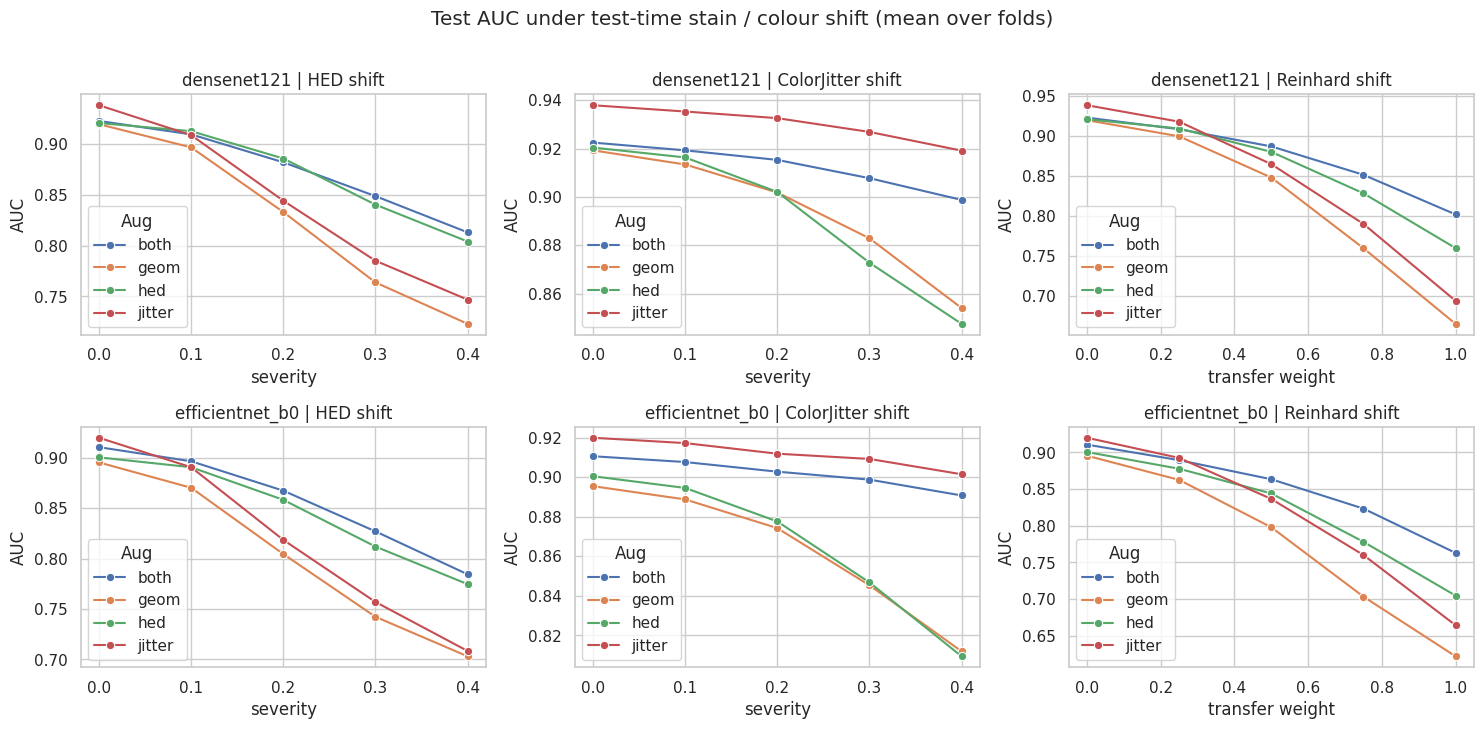

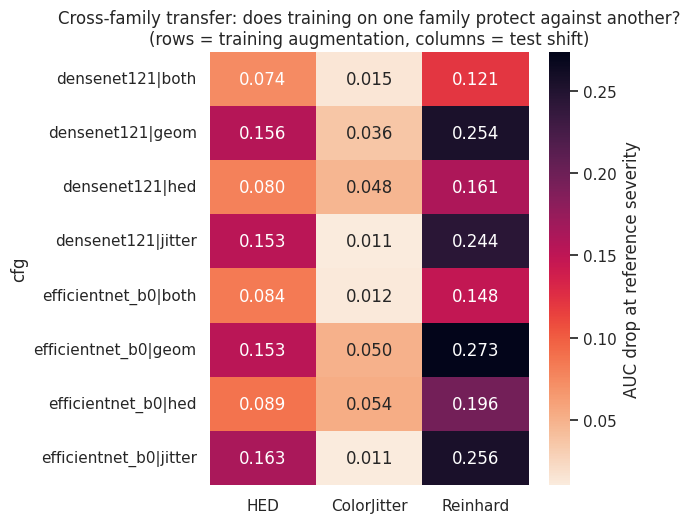

In [15]:
recs = []
for (seed, fold, model, aug), r in ALL.items():
    for (kind, lvl), p in r["shift_p"].items():
        recs.append(dict(Model=model, Aug=aug, kind=kind, level=lvl, F1=f1_at(r["y"], p), AUC=auc_safe(r["y"], p)))
sh = pd.DataFrame(recs).groupby(["Model", "Aug", "kind", "level"], as_index=False).mean()
sh.to_csv(f"{OUT}/shift_curves.csv", index=False)

mods = [m for m in sh.Model.unique() if m != "ensemble"]; kinds = list(SHIFT)
fig, axes = plt.subplots(len(mods), len(kinds), figsize=(5 * len(kinds), 3.6 * len(mods)), squeeze=False)
for i, m in enumerate(mods):
    for j, kd in enumerate(kinds):
        d = sh[(sh.Model == m) & (sh.kind == kd)]
        sns.lineplot(data=d, x="level", y="AUC", hue="Aug", marker="o", ax=axes[i, j])
        axes[i, j].set_title(f"{m} | {kd} shift"); axes[i, j].set_xlabel("severity" if kd != "Reinhard" else "transfer weight")
fig.suptitle("Test AUC under test-time stain / colour shift (mean over folds)", y=1.01)
fig.tight_layout(); fig.savefig(f"{OUT}/shift_curves.png", dpi=150, bbox_inches="tight"); plt.show()

tm = res[res.Model != "ensemble"].assign(cfg=lambda d: d.Model + "|" + d.Aug).groupby("cfg")[[f"dAUC_{k}" for k in SHIFT]].mean()
tm.columns = [c.replace("dAUC_", "") for c in tm.columns]
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(tm) + 1.8))
sns.heatmap(tm, annot=True, fmt=".3f", cmap="rocket_r", cbar_kws=dict(label="AUC drop at reference severity"), ax=ax)
ax.set_title("Cross-family transfer: does training on one family protect against another?\n(rows = training augmentation, columns = test shift)")
fig.tight_layout(); fig.savefig(f"{OUT}/transfer_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Calibration note (temperature scaling vs. raw)
Run 2 suggested that a temperature fitted on ~12 validation patients does not transfer to new patients. Paired comparison across runs (negative = temperature scaling helped):

In [16]:
cal = res[res.Model != "ensemble"].assign(delta=lambda d: d.ECE_ts - d.ECE_raw)
print(f"ECE(TS) - ECE(raw): mean {cal.delta.mean():+.4f}, TS better in {(cal.delta < 0).mean():.0%} of {len(cal)} runs")
display(cal.groupby(["Model", "Aug"])[["ECE_raw", "ECE_ts", "delta"]].mean().round(4))

ECE(TS) - ECE(raw): mean +0.0097, TS better in 28% of 40 runs


ECE_raw  ECE_ts   delta
Model           Aug                            
densenet121     both     0.0455  0.0476  0.0021
                geom     0.0505  0.0524  0.0019
                hed      0.0495  0.0524  0.0029
                jitter   0.0450  0.0481  0.0031
efficientnet_b0 both     0.0471  0.0644  0.0173
                geom     0.0512  0.0670  0.0157
                hed      0.0532  0.0684  0.0152
                jitter   0.0489  0.0686  0.0196

## 11. Statistical rigor: patient-clustered bootstrap and ranking stability (H1, H4)

**Bootstrap.** Predictions from all folds are pooled (every image is predicted once per seed, by a model that never saw its patient). Patients are resampled with replacement, and paired differences between augmentations are computed on the *same* resample. AUC and balanced accuracy are used because the class mix differs between folds. Scenarios: clean and each shift family at its reference severity.

**Ranking stability.** AUC rank of every (model, augmentation) configuration in each fold, and the Kendall τ between folds' rankings (τ near 1 = rankings agree; near 0 = a single split tells you little).

In [17]:
def pooled(model, aug, getter):
    keys = sorted(k for k in ALL if k[2] == model and k[3] == aug)
    return (np.concatenate([ALL[k]["y"] for k in keys]), np.concatenate([getter(ALL[k]) for k in keys]),
            np.concatenate([ALL[k]["patient"] for k in keys]))

def balacc(y, p): 
    pred = p >= 0.5; return 0.5 * (pred[y == 1].mean() + (~pred[y == 0]).mean())

SCEN = {"clean": lambda r: r["p"]}
for kd in SHIFT: SCEN[f"{kd}@{REF[kd]}"] = (lambda kd: (lambda r: r["shift_p"][(kd, float(REF[kd]))]))(kd)
PAIRS = [(a, b) for a, b in [("jitter", "geom"), ("hed", "geom"), ("both", "geom"), ("hed", "jitter"), ("both", "jitter"), ("both", "hed")]
         if a in CFG["AUGS"] and b in CFG["AUGS"]]

def boot_compare(model, B, seed=0):
    augs = sorted({a for pr in PAIRS for a in pr}); data = {(a, s): pooled(model, a, g) for a in augs for s, g in SCEN.items()}
    y, _, pat = next(iter(data.values()))
    for v in data.values(): assert (v[0] == y).all() and (v[2] == pat).all()
    upat = pd.unique(pat); idx_by = {u: np.where(pat == u)[0] for u in upat}; rng = np.random.RandomState(seed)
    st = {k: {"AUC": [], "BalAcc": []} for k in data}
    for _ in range(B):
        sel = rng.choice(len(upat), len(upat), replace=True); idx = np.concatenate([idx_by[upat[i]] for i in sel]); yb = y[idx]
        ok = yb.min() != yb.max()
        for k, (_, p, _) in data.items():
            st[k]["AUC"].append(roc_auc_score(yb, p[idx]) if ok else np.nan); st[k]["BalAcc"].append(balacc(yb, p[idx]) if ok else np.nan)
    rows = []
    for s in SCEN:
        for met in ("AUC", "BalAcc"):
            for a, b in PAIRS:
                d = np.array(st[(a, s)][met]) - np.array(st[(b, s)][met])
                lo, md_, hi = np.nanpercentile(d, [2.5, 50, 97.5])
                rows.append(dict(Model=model, Scenario=s, Metric=met, Comparison=f"{a} - {b}", Median=md_, CI_lo=lo, CI_hi=hi, Excludes0=bool(lo > 0 or hi < 0)))
    absolute = []
    for (a, s), v in data.items():
        for met in ("AUC", "BalAcc"):
            lo, md_, hi = np.nanpercentile(st[(a, s)][met], [2.5, 50, 97.5])
            absolute.append(dict(Model=model, Aug=a, Scenario=s, Metric=met, Median=md_, CI_lo=lo, CI_hi=hi))
    return pd.DataFrame(rows), pd.DataFrame(absolute)

bd, ba = [], []
for m in [m for m in CFG["MODELS"] if m in {k[2] for k in ALL}]:
    d, a = boot_compare(m, CFG["N_BOOT"]); bd.append(d); ba.append(a)
boot_diff, boot_abs = pd.concat(bd, ignore_index=True), pd.concat(ba, ignore_index=True)
boot_diff.to_csv(f"{OUT}/bootstrap_paired_differences.csv", index=False); boot_abs.to_csv(f"{OUT}/bootstrap_absolute.csv", index=False)
pd.set_option("display.width", 200, "display.max_rows", 300)
print("Paired differences (95% patient-cluster bootstrap CI); Excludes0=True means the CI does not cross 0")
display(boot_diff[boot_diff.Metric == "AUC"].round(4).reset_index(drop=True))

Paired differences (95% patient-cluster bootstrap CI); Excludes0=True means the CI does not cross 0


,Model,Scenario,Metric,Comparison,Median,CI_lo,CI_hi,Excludes0
0,densenet121,clean,AUC,jitter - geom,0.0297,0.0048,0.0648,True
1,densenet121,clean,AUC,hed - geom,0.0089,-0.0130,0.0468,False
2,densenet121,clean,AUC,both - geom,0.0021,-0.0302,0.0355,False
3,densenet121,clean,AUC,hed - jitter,-0.0191,-0.0393,-0.0032,True
4,densenet121,clean,AUC,both - jitter,-0.0269,-0.0519,-0.0064,True
5,densenet121,clean,AUC,both - hed,-0.0077,-0.0305,0.0129,False
6,densenet121,HED@0.3,AUC,jitter - geom,0.0259,-0.0097,0.0619,False
7,densenet121,HED@0.3,AUC,hed - geom,0.0768,0.0504,0.1077,True
8,densenet121,HED@0.3,AUC,both - geom,0.0841,0.0472,0.1225,True
9,densenet121,HED@0.3,AUC,hed - jitter,0.0527,0.0261,0.0793,True


Kendall tau between folds' rankings: mean 0.43 (min 0.14, max 0.64) over 10 fold pairs


,AUC_mean,AUC_min,AUC_max,rank_best,rank_worst
cfg,,,,,
densenet121|jitter,0.938,0.884,0.980,1.0,3.0
densenet121|both,0.922,0.849,0.974,1.0,7.0
densenet121|hed,0.920,0.830,0.980,2.0,4.0
efficientnet_b0|jitter,0.920,0.829,0.987,1.0,5.0
densenet121|geom,0.919,0.832,0.978,2.0,6.0
efficientnet_b0|both,0.911,0.814,0.977,5.0,7.0
efficientnet_b0|hed,0.900,0.818,0.967,6.0,8.0
efficientnet_b0|geom,0.895,0.781,0.976,6.0,8.0


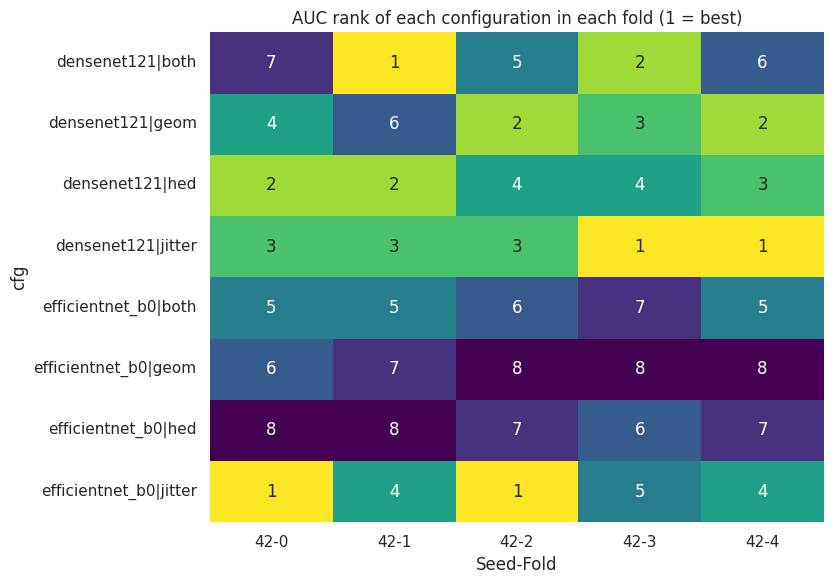

In [18]:
cfgtab = res[res.Model != "ensemble"].assign(cfg=lambda d: d.Model + "|" + d.Aug).pivot_table(index="cfg", columns=["Seed", "Fold"], values="AUC")
rank_tab = cfgtab.rank(ascending=False); cols = list(cfgtab.columns)
if len(cols) >= 2 and len(cfgtab) >= 3:
    taus = [kendalltau(cfgtab[a], cfgtab[b])[0] for a, b in itertools.combinations(cols, 2)]
    print(f"Kendall tau between folds' rankings: mean {np.nanmean(taus):.2f} (min {np.nanmin(taus):.2f}, max {np.nanmax(taus):.2f}) over {len(taus)} fold pairs")
    spread = pd.DataFrame(dict(AUC_mean=cfgtab.mean(1), AUC_min=cfgtab.min(1), AUC_max=cfgtab.max(1), rank_best=rank_tab.min(1), rank_worst=rank_tab.max(1))).round(3)
    display(spread.sort_values("AUC_mean", ascending=False))
    fig, ax = plt.subplots(figsize=(1.1 * len(cols) + 3, 0.5 * len(cfgtab) + 2))
    sns.heatmap(rank_tab, annot=True, fmt=".0f", cmap="viridis_r", cbar=False, ax=ax); ax.set_title("AUC rank of each configuration in each fold (1 = best)")
    fig.tight_layout(); fig.savefig(f"{OUT}/ranking_stability.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("Need >= 2 folds and >= 3 configurations for the ranking-stability analysis.")

## 12. Operating-point transfer and patient-level conformal risk control (H2)

**Question:** if you must catch ≥ (1−α) of malignant cases, which way of choosing the threshold actually delivers that on *new patients*?

All three methods are scored by the same quantity, **mean per-patient miss rate (FNR) over held-out malignant patients**, to be compared with α; each also has a specificity cost.

1. **Validation-tuned** — threshold giving sensitivity ≥ 1−α on the fold's validation images (what run 2 did).
2. **Naive pooled** — α-quantile of malignant-image scores from *other* patients, no correction, images weighted equally.
3. **Patient-level CRC** — conformal risk control (Angelopoulos et al., 2022) with the *patient* as the exchangeable unit: loss = a patient's miss rate; choose the largest threshold with ((n−1)·R̂₋ⱼ(t)+1)/n ≤ α, calibrated on out-of-fold predictions of all *other* patients (leave-one-patient-out). In expectation over patients, mean FNR ≤ α. A guarantee is impossible when n < 1/α, flagged `feasible=False` (the method then falls back to flagging everything malignant).

Caveats: out-of-fold scores come from different fold models (a "cross-conformal" approximation to exchangeability), and one seed's CV uses each patient once. The expectation guarantee is marginal, so look at the mean across patients, not individual folds.

Target: mean patient FNR <= alpha. Higher spec at equal FNR is better. feasible = (#malignant patients >= 1/alpha).


Val_FNR  Naive_FNR  CRC_FNR  Val_spec  Naive_spec  CRC_spec  feasible  n_mal_patients
Model           Aug       alpha                                                                                       
densenet121     both      0.02    0.0461     0.0280   0.0039    0.5988      0.4129    0.1214       1.0            58.0
                          0.05    0.0782     0.0617   0.0380    0.7185      0.6375    0.4940       1.0            58.0
                          0.10    0.1246     0.1111   0.0867    0.8044      0.7601    0.7040       1.0            58.0
                          0.20    0.2213     0.2069   0.1885    0.8855      0.8726    0.8585       1.0            58.0
                geom      0.02    0.0400     0.0280   0.0045    0.5863      0.5081    0.0879       1.0            58.0
                          0.05    0.0677     0.0623   0.0365    0.7085      0.6883    0.5798       1.0            58.0
                          0.10    0.1095     0.1134   0.0879    0.7681      0.7770    0.7383       1.0            58.0
                          0.20    0.1878     0.2072   0.1882    0.8456      0.8617    0.8480       1.0            58.0
                hed       0.02    0.0259     0.0260   0.0031    0.4790      0.4690    0.2008       1.0            58.0
                          0.05    0.0590     0.0584   0.0356    0.6444      0.6460    0.5343       1.0            58.0
                          0.10    0.0947     0.1068   0.0885    0.7435      0.7778    0.7286       1.0            58.0
                          0.20    0.1688     0.2026   0.1884    0.8411      0.8851    0.8782       1.0            58.0
                jitter    0.02    0.0476     0.0291   0.0042    0.6710      0.5294    0.1210       1.0            58.0
                          0.05    0.0801     0.0609   0.0371    0.7762      0.7468    0.6052       1.0            58.0
                          0.10    0.1253     0.1107   0.0878    0.8508      0.8363    0.8004       1.0            58.0
                          0.20    0.2103     0.2045   0.1887    0.9181      0.9214    0.9133       1.0            58.0
efficientnet_b0 both      0.02    0.0368     0.0292   0.0037    0.5222      0.4383    0.1710       1.0            58.0
                          0.05    0.0758     0.0598   0.0373    0.6774      0.6367    0.4968       1.0            58.0
                          0.10    0.1232     0.1098   0.0881    0.7790      0.7565    0.7073       1.0            58.0
                          0.20    0.2132     0.2030   0.1876    0.8601      0.8480    0.8435       1.0            58.0
                geom      0.02    0.0350     0.0264   0.0053    0.5206      0.4661    0.1488       1.0            58.0
                          0.05    0.0650     0.0577   0.0348    0.6270      0.6210    0.5246       1.0            58.0
                          0.10    0.1055     0.1089   0.0878    0.7226      0.7310    0.6923       1.0            58.0
                          0.20    0.1850     0.2017   0.1876    0.8036      0.8294    0.8210       1.0            58.0
                hed       0.02    0.0378     0.0285   0.0038    0.4887      0.4016    0.1089       1.0            58.0
                          0.05    0.0733     0.0646   0.0378    0.6427      0.5996    0.4569       1.0            58.0
                          0.10    0.1127     0.1146   0.0868    0.7323      0.7258    0.6661       1.0            58.0
                          0.20    0.1751     0.2096   0.1888    0.8234      0.8448    0.8262       1.0            58.0
                jitter    0.02    0.0424     0.0301   0.0039    0.6363      0.5395    0.2145       1.0            58.0
                          0.05    0.0742     0.0635   0.0390    0.7395      0.7125    0.5911       1.0            58.0
                          0.10    0.1133     0.1103   0.0874    0.8032      0.8044    0.7702       1.0            58.0
                          0.20    0.1795     0.2025   0.1893    0.8560      0.8839    0.8722       1.0    

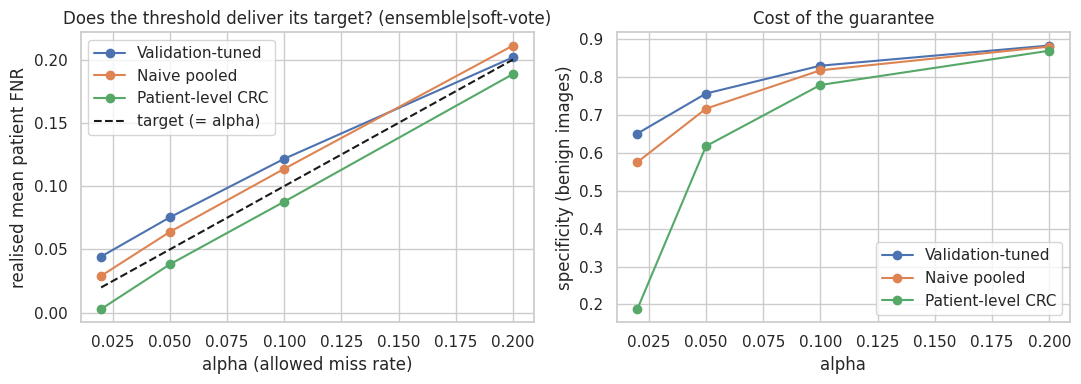

In [19]:
GRID = np.linspace(0, 1, 2001)
def patient_arrays(y, p, pat):
    mal = {u: np.sort(p[(pat == u) & (y == 1)]) for u in pd.unique(pat[y == 1])}
    return mal, p[y == 0]

def crc_lopo(mal, ben, alphas):
    names = list(mal); n = len(names)
    L = np.stack([np.searchsorted(mal[u], GRID, side="left") / len(mal[u]) for u in names]); S = L.sum(0)   # L[j,t] = patient j's miss rate at threshold t
    allm = np.sort(np.concatenate(list(mal.values()))); M = len(allm); out = {}
    for a in alphas:
        cond = ((S[None, :] - L + 1.0) / n) <= a                      # CRC rule with patient j left out (monotone: True...True False...)
        idx = np.maximum(cond.sum(1) - 1, 0); crc_fnr = float(L[np.arange(n), idx].mean())
        t_full = GRID[max(int((((S + 1.0) / (n + 1.0)) <= a).sum()) - 1, 0)]
        nv = []
        for u in names:
            oth = np.sort(np.concatenate([mal[v] for v in names if v != u])); t = oth[min(int(np.floor(a * len(oth))), len(oth) - 1)]
            nv.append(np.searchsorted(mal[u], t, side="left") / len(mal[u]))
        t_n = allm[min(int(np.floor(a * M)), M - 1)]
        out[a] = dict(CRC_FNR=crc_fnr, CRC_spec=float((ben < t_full).mean()), feasible=bool(n >= 1 / a),
                      Naive_FNR=float(np.mean(nv)), Naive_spec=float((ben < t_n).mean()), n_mal_patients=n)
    return out

def val_tuned(runs, alphas):
    loss = {a: [] for a in alphas}; ben = {a: [] for a in alphas}
    for r in runs:
        if len(set(r["val_y"])) < 2: continue
        fpr, tpr, thr = roc_curve(r["val_y"], r["val_p"]); y, p, pat = r["y"], r["p"], r["patient"]
        for a in alphas:
            t = min(float(thr[int(np.argmax(tpr >= 1 - a))]), 1.0)
            loss[a] += [float(np.mean(p[(pat == u) & (y == 1)] < t)) for u in pd.unique(pat[y == 1])]; ben[a].append(p[y == 0] < t)
    return {a: dict(Val_FNR=float(np.mean(loss[a])), Val_spec=float(np.mean(np.concatenate(ben[a])))) for a in alphas}

rows = []
for model, aug in sorted({(k[2], k[3]) for k in ALL}):
    for seed in sorted({k[0] for k in ALL}):
        ks = sorted(k for k in ALL if k[0] == seed and k[2] == model and k[3] == aug)
        if len(ks) < 2: continue
        y = np.concatenate([ALL[k]["y"] for k in ks]); p = np.concatenate([ALL[k]["p"] for k in ks]); pat = np.concatenate([ALL[k]["patient"] for k in ks])
        mal, ben = patient_arrays(y, p, pat)
        if len(mal) < 3: continue
        c = crc_lopo(mal, ben, CFG["ALPHAS"]); v = val_tuned([ALL[k] for k in ks], CFG["ALPHAS"])
        for a in CFG["ALPHAS"]: rows.append(dict(Model=model, Aug=aug, Seed=seed, alpha=a, **c[a], **v[a]))
crc = pd.DataFrame(rows)
if len(crc):
    crc_tab = crc.groupby(["Model", "Aug", "alpha"]).mean(numeric_only=True).drop(columns=["Seed"]).round(4); crc_tab.to_csv(f"{OUT}/threshold_transfer.csv")
    print("Target: mean patient FNR <= alpha. Higher spec at equal FNR is better. feasible = (#malignant patients >= 1/alpha).")
    display(crc_tab[["Val_FNR", "Naive_FNR", "CRC_FNR", "Val_spec", "Naive_spec", "CRC_spec", "feasible", "n_mal_patients"]])
    best_cfg = res[res.Model != "ensemble"].groupby(["Model", "Aug"]).AUC.mean().idxmax()
    sel = ("ensemble", "soft-vote") if ("ensemble", "soft-vote") in {(k[2], k[3]) for k in ALL} else best_cfg
    d = crc[(crc.Model == sel[0]) & (crc.Aug == sel[1])].groupby("alpha").mean(numeric_only=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for nm, col in (("Validation-tuned", "Val_FNR"), ("Naive pooled", "Naive_FNR"), ("Patient-level CRC", "CRC_FNR")): axes[0].plot(d.index, d[col], "o-", label=nm)
    axes[0].plot(d.index, d.index, "k--", label="target (= alpha)"); axes[0].set_xlabel("alpha (allowed miss rate)"); axes[0].set_ylabel("realised mean patient FNR")
    axes[0].set_title(f"Does the threshold deliver its target? ({sel[0]}|{sel[1]})"); axes[0].legend()
    for nm, col in (("Validation-tuned", "Val_spec"), ("Naive pooled", "Naive_spec"), ("Patient-level CRC", "CRC_spec")): axes[1].plot(d.index, d[col], "o-", label=nm)
    axes[1].set_xlabel("alpha"); axes[1].set_ylabel("specificity (benign images)"); axes[1].set_title("Cost of the guarantee"); axes[1].legend()
    fig.tight_layout(); fig.savefig(f"{OUT}/threshold_transfer.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("Not enough folds / malignant patients for the threshold analysis.")

## 13. Abstention: does stain-perturbation disagreement beat max-softmax? (H3)

For each test image, five uncertainty scores are computed on the (optionally shifted) input; the *base* prediction is the single clean-view prediction in every case, so only the quality of the uncertainty ranking differs:

* `MSP` — 1 − max softmax of the single view (standard baseline);
* `TTA-HED std / entropy` — spread / predictive entropy over K random HED-perturbed views;
* `TTA-DIH std / entropy` — the same over K dihedral views (**control**: is it the stain perturbation, or just any test-time augmentation?).

Metrics (per run, then averaged): **AUROC** of the score for detecting errors (higher better), **AURC** area under the risk–coverage curve (lower better), and accuracy at 90 % / 80 % coverage. Conditions include Reinhard shift (independent of every training augmentation).

Mean over runs (every model x augmentation x fold). beats_MSP = share of runs with lower AURC than MSP.


AUROC    AURC   Acc90   Acc80  beats_MSP  base_acc
Cond         Score                                                               
HED@0.3      MSP              0.6443  0.1989  0.7588  0.7791      0.000    0.7359
             TTA-DIH entropy  0.6701  0.1865  0.7603  0.7842      0.850    0.7359
             TTA-DIH std      0.6746  0.1769  0.7563  0.7786      0.925    0.7359
             TTA-HED entropy  0.6804  0.1745  0.7585  0.7821      1.000    0.7359
             TTA-HED std      0.6979  0.1572  0.7562  0.7799      0.975    0.7359
Reinhard@0.5 MSP              0.7052  0.1284  0.8121  0.8357      0.000    0.7853
             TTA-DIH entropy  0.7477  0.1125  0.8159  0.8454      0.950    0.7853
             TTA-DIH std      0.7338  0.1128  0.8096  0.8341      0.775    0.7853
             TTA-HED entropy  0.7077  0.1233  0.8072  0.8301      0.675    0.7853
             TTA-HED std      0.6897  0.1241  0.8024  0.8198      0.575    0.7853
Reinhard@1.0 MSP              0.5842  0.3041  0.6710  0.6855      0.000    0.6559
             TTA-DIH entropy  0.6053  0.2926  0.6726  0.6906      0.650    0.6559
             TTA-DIH std      0.6193  0.2754  0.6703  0.6866      0.950    0.6559
             TTA-HED entropy  0.6281  0.2675  0.6722  0.6899      1.000    0.6559
             TTA-HED std      0.6387  0.2499  0.6728  0.6898      1.000    0.6559
clean@0.0    MSP              0.7370  0.0774  0.8793  0.8987      0.000    0.8498
             TTA-DIH entropy  0.7822  0.0679  0.8853  0.9097      0.900    0.8498
             TTA-DIH std      0.7731  0.0676  0.8780  0.9004      0.750    0.8498
             TTA-HED entropy  0.7313  0.0778  0.8723  0.8927      0.525    0.8498
             TTA-HED std      0.6908  0.0841  0.8613  0.8752      0.425    0.8498

Score                   MSP  TTA-DIH entropy  TTA-DIH std  TTA-HED entropy  TTA-HED std
Aug    Cond                                                                            
both   HED@0.3       0.1652           0.1514       0.1465           0.1539       0.1370
       Reinhard@0.5  0.1291           0.1090       0.1102           0.1228       0.1175
       Reinhard@1.0  0.2410           0.2222       0.2114           0.2229       0.2103
       clean@0.0     0.0854           0.0719       0.0740           0.0847       0.0866
geom   HED@0.3       0.2387           0.2294       0.2134           0.2104       0.1916
       Reinhard@0.5  0.1489           0.1372       0.1327           0.1447       0.1466
       Reinhard@1.0  0.3723           0.3707       0.3431           0.3260       0.3032
       clean@0.0     0.0830           0.0754       0.0708           0.0859       0.0938
hed    HED@0.3       0.1596           0.1486       0.1460           0.1489       0.1408
       Reinhard@0.5  0.1192           0.1037       0.1037           0.1117       0.1105
       Reinhard@1.0  0.2643           0.2544       0.2411           0.2390       0.2262
       clean@0.0     0.0814           0.0714       0.0710           0.0773       0.0800
jitter HED@0.3       0.2320           0.2167       0.2017           0.1848       0.1593
       Reinhard@0.5  0.1164           0.1002       0.1048           0.1141       0.1218
       Reinhard@1.0  0.3389           0.3231       0.3057           0.2822       0.2599
       clean@0.0     0.0598           0.0528       0.0546           0.0634       0.0760

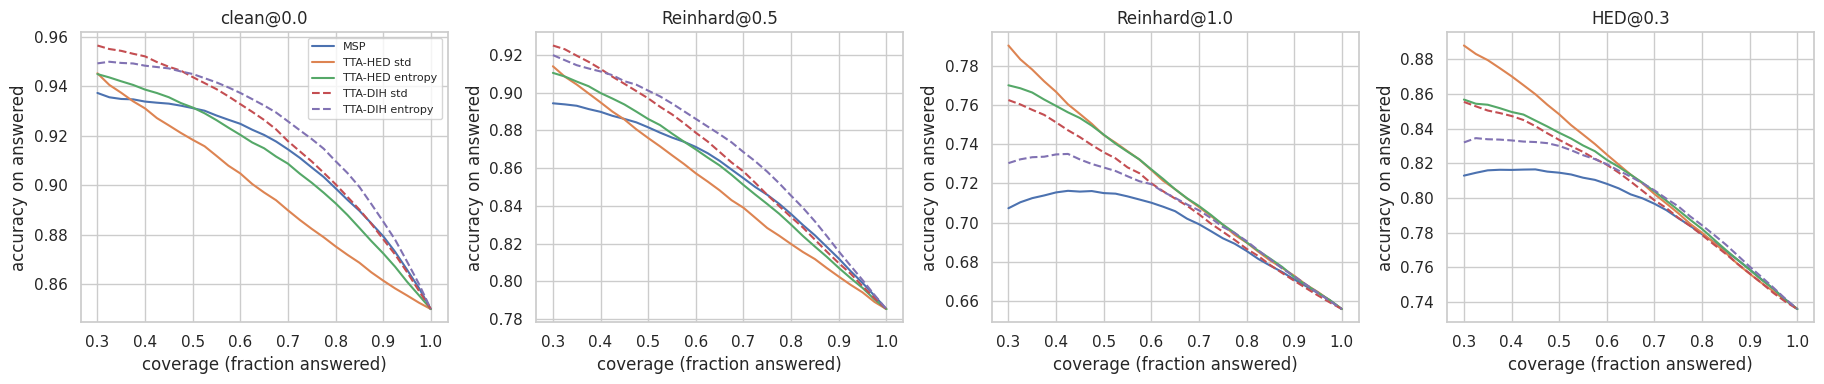

In [20]:
def _ent(p): p = np.clip(p, 1e-6, 1 - 1e-6); return -(p * np.log(p) + (1 - p) * np.log(1 - p))
def unc_scores(a):
    out = {"MSP": 1 - np.maximum(a["p"], 1 - a["p"])}
    for tag, P in (("TTA-HED", a["P_hed"]), ("TTA-DIH", a["P_dih"])): out[f"{tag} std"] = P.std(0); out[f"{tag} entropy"] = _ent(P.mean(0))
    return out
COVG = np.linspace(0.3, 1.0, 29)
def sel_curve(correct, unc):
    c = correct[np.argsort(unc, kind="stable")]; return np.cumsum(c) / np.arange(1, len(c) + 1)
def sel_metrics(correct, unc):
    cum = sel_curve(correct, unc); err = ~correct
    auroc = roc_auc_score(err, unc) if 0 < err.sum() < len(err) else np.nan
    at = lambda cov: cum[max(int(round(cov * len(cum))), 1) - 1]
    return dict(AUROC=auroc, AURC=float(np.mean(1 - cum)), Acc90=float(at(0.9)), Acc80=float(at(0.8))), np.array([at(c) for c in COVG])

recs, curves = [], {}
for (seed, fold, model, aug), r in RUNS.items():
    for cond, a in r["abst"].items():
        correct = (a["p"] >= 0.5).astype(int) == r["y"]
        for sc, u in unc_scores(a).items():
            m, cv = sel_metrics(correct, u); recs.append(dict(Seed=seed, Fold=fold, Model=model, Aug=aug, Cond=cond, Score=sc, **m, base_acc=correct.mean()))
            curves.setdefault((cond, sc), []).append(cv)
ab = pd.DataFrame(recs); ab.to_csv(f"{OUT}/abstention_per_run.csv", index=False)
if len(ab):
    msp = ab[ab.Score == "MSP"].set_index(["Seed", "Fold", "Model", "Aug", "Cond"]).AURC
    ab["beats_MSP"] = [a < msp.loc[(s, f, m, au, c)] for a, s, f, m, au, c in zip(ab.AURC, ab.Seed, ab.Fold, ab.Model, ab.Aug, ab.Cond)]
    summ = ab.groupby(["Cond", "Score"])[["AUROC", "AURC", "Acc90", "Acc80", "beats_MSP", "base_acc"]].mean().round(4)
    print("Mean over runs (every model x augmentation x fold). beats_MSP = share of runs with lower AURC than MSP."); display(summ)
    display(ab.groupby(["Aug", "Cond", "Score"])[["AUROC", "AURC", "Acc90"]].mean().round(4).unstack("Score")["AURC"])
    conds = list(dict.fromkeys(ab.Cond)); fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 4), squeeze=False)
    for ax, cd in zip(axes[0], conds):
        for sc in ["MSP", "TTA-HED std", "TTA-HED entropy", "TTA-DIH std", "TTA-DIH entropy"]:
            ax.plot(COVG, np.mean(curves[(cd, sc)], 0), label=sc, ls="--" if "DIH" in sc else "-")
        ax.set_title(cd); ax.set_xlabel("coverage (fraction answered)"); ax.set_ylabel("accuracy on answered")
    axes[0, 0].legend(fontsize=8); fig.tight_layout(); fig.savefig(f"{OUT}/abstention_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 14. Side analyses: adversarial sanity check and external set

In [21]:
advs = [r["adv"].assign(Model=r["model"], Aug=r["aug"], Fold=r["fold"]) for r in RUNS.values() if r.get("adv") is not None]
if advs:
    adv = pd.concat(advs); adv.to_csv(f"{OUT}/adversarial_sanity.csv", index=False)
    print("Adversarial sanity check (small subset; eps in /255 pixel units). Undefended CNNs collapse, which is already documented in computational pathology.")
    display(adv.pivot_table(index=["Model", "Aug"], columns=["attack", "eps"], values="acc").round(3))
exts = [dict(Model=r["model"], Aug=r["aug"], Fold=r["fold"], **{k: v for k, v in r["ext"].items() if k in ("Accuracy", "Recall", "Specificity", "F1", "AUC")}) for r in RUNS.values() if r.get("ext")]
if exts:
    ex = pd.DataFrame(exts); ex.to_csv(f"{OUT}/external_eval.csv", index=False)
    print("External dataset (threshold 0.5): the closest thing to a real cross-site stain shift in this notebook"); display(ex.groupby(["Model", "Aug"]).mean(numeric_only=True).round(3))
else:
    print("No external set configured (CFG['EXTERNAL_DIR']); cross-site claims therefore cannot be made from this run.")

Adversarial sanity check (small subset; eps in /255 pixel units). Undefended CNNs collapse, which is already documented in computational pathology.


attack                   FGSM           PGD       clean
eps                       1.0    2.0    1.0  2.0    0.0
Model           Aug                                    
densenet121     both    0.180  0.140  0.000  0.0  0.920
                geom    0.387  0.347  0.020  0.0  0.920
                hed     0.367  0.287  0.033  0.0  0.953
                jitter  0.327  0.293  0.020  0.0  0.967
efficientnet_b0 both    0.167  0.140  0.000  0.0  0.860
                geom    0.440  0.420  0.007  0.0  0.920
                hed     0.333  0.313  0.000  0.0  0.900
                jitter  0.300  0.307  0.000  0.0  0.927

No external set configured (CFG['EXTERNAL_DIR']); cross-site claims therefore cannot be made from this run.
